Assignment 1: Exploratory Data Analysis (EDA)
**Course:** Introduction to Data Science
**Student Name:** Helen Barkan
**ID:** 207353533

2.2 Data Source Description
* **Data Source:** Kaggle (Tourism and Economic Impact Dataset).
* **Purpose of Collection:**Tracking international tourism trends, economic impact, and passenger arrivals across different countries over time.
* **Collecting Entity:** The specific organization collecting the data is not explicitly mentioned on the Kaggle page, which is a notable missing piece of metadata.
* **Domain Knowledge:** As someone who loves to travel, I expect to see strong relationships between a country's economic status (GDP) and its tourism receipts.

In [5]:
import pandas as pd
df=pd.read_csv("tourism.csv")
print(df.head())
 

                       country country_code  year  tourism_receipts  \
0                        Aruba          ABW  1999      7.820000e+08   
1  Africa Eastern and Southern          AFE  1999      8.034209e+09   
2                  Afghanistan          AFG  1999               NaN   
3   Africa Western and Central          AFW  1999      1.443613e+09   
4                       Angola          AGO  1999      3.100000e+07   

   tourism_arrivals  tourism_exports  tourism_departures  \
0      9.720000e+05        62.542949                 NaN   
1      1.530938e+07        12.204030                 NaN   
2               NaN              NaN                 NaN   
3      3.897975e+06         3.974476                 NaN   
4      4.500000e+04         0.583858                 NaN   

   tourism_expenditures           gdp   inflation  unemployment  
0              9.495387  1.722905e+09    2.280372           NaN  
1              7.760536  2.654293e+11    7.819865           NaN  
2             

3. Meta-Analysis and Data Structure
3.1 File Analysis
* **File Size:** ~682 KB.
* **Format:** CSV.
* **Creation Date:** Created and uploaded to Kaggle around 2024 (Note: the recorded data covers the years 1999-2023).
* **Data Purpose:** To provide historical data on global tourism metrics and economic impacts.

In [4]:
print(df.shape)
df.info()

(6650, 11)
<class 'pandas.DataFrame'>
RangeIndex: 6650 entries, 0 to 6649
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   country               6650 non-null   str    
 1   country_code          6650 non-null   str    
 2   year                  6650 non-null   int64  
 3   tourism_receipts      4289 non-null   float64
 4   tourism_arrivals      4949 non-null   float64
 5   tourism_exports       4114 non-null   float64
 6   tourism_departures    2589 non-null   float64
 7   tourism_expenditures  4173 non-null   float64
 8   gdp                   6424 non-null   float64
 9   inflation             5668 non-null   float64
 10  unemployment          3658 non-null   float64
dtypes: float64(8), int64(1), str(2)
memory usage: 571.6 KB


3.2 Data Structure Discussion
* **Rows and Columns:** The dataset contains 6,650 rows and 11 columns.
* **Column Names:** The column names are highly logical, formatted in lowercase with underscores, which is ideal for coding.
* **Data Types:** The types match expectations. `country` is text (categorical), `year` is an integer, and financial/population metrics are floats. 
* **Data Collection & Biases:** The data was likely collected for operational macroeconomic tracking. A significant potential bias is that less developed countries might have weaker reporting systems, leading to the missing data (NaNs) we observed in certain columns.

4. Data Quality and Integrity

In [6]:
df.isnull().sum()


country                    0
country_code               0
year                       0
tourism_receipts        2361
tourism_arrivals        1701
tourism_exports         2536
tourism_departures      4061
tourism_expenditures    2477
gdp                      226
inflation                982
unemployment            2992
dtype: int64

4.1 Missing Data
* **Scope of Missing Data:** There is a massive amount of missing data in specific columns. For instance, `tourism_departures` is missing 4,061 values (over 60% of the dataset), while `gdp` is only missing 226 values.
* **Pattern:** The missing data is structured, likely Missing Not at Random (MNAR) rather than Missing Completely at Random (MCAR). 
* **Insights from Missingness:** The pattern suggests that less developed countries, or countries experiencing instability, may lack the infrastructure or resources to consistently track and report detailed tourism metrics every single year.
* **Imputation Strategy:** 
  - For continuous columns with minimal missing values (like `gdp`), we can use simple statistical imputation by replacing the missing values with the median or mean.
  - For columns with extreme missingness (like `tourism_departures`), we might consider removing the column entirely, or using advanced machine learning imputation methods like KNN or MICE.

In [12]:

print("Full duplicates:", df.duplicated().sum())
print("Partial duplicates:", df.duplicated(subset=['country', 'year']).sum())

Full duplicates: 0
Partial duplicates: 0


4.2 Duplicates
* **Full Duplicates:** 0 rows.
* **Partial Duplicates:** 0 rows (when checking for overlapping 'country' and 'year' combinations).
* **Insights:** The complete absence of duplicates indicates that the dataset is well-structured at a strict granularity of one record per country per year. This suggests the data was pre-aggregated and properly cleaned before publication.

In [14]:
df.describe()

,year,tourism_receipts,tourism_arrivals,tourism_exports,tourism_departures,tourism_expenditures,gdp,inflation,unemployment
count,6650.000000,4.289000e+03,4.949000e+03,4114.000000,2.589000e+03,4173.000000,6.424000e+03,5668.000000,3658.000000
mean,2011.000000,3.062956e+10,6.263894e+07,15.506851,8.246093e+07,6.652740,2.089999e+12,6.319369,7.961191
std,7.211645,1.291076e+11,2.049444e+08,17.758374,2.064665e+08,4.071632,7.761985e+12,18.682769,5.802565
min,1999.000000,1.000000e+05,9.000000e+02,0.000956,2.000000e+03,0.157818,1.396473e+07,-16.859691,0.039000
25%,2005.000000,2.690000e+08,5.290000e+05,4.657732,1.051000e+06,4.074702,6.087182e+09,1.865425,4.250000
50%,2011.000000,1.553000e+09,2.508000e+06,8.306797,4.634000e+06,5.754790,3.681803e+10,3.629433,6.548000
75%,2017.000000,9.144227e+09,1.818000e+07,18.506710,4.508703e+07,7.985102,4.266977e+11,6.563197,9.894692
max,2023.000000,1.863069e+12,2.403074e+09,101.966999,2.034432e+09,28.192276,1.061717e+14,557.201817,57.000000


4.3 Suspicious Values
* **Impossible or Negative Values:** A review of the minimum values shows no impossible negative counts for physical metrics (like tourist arrivals or GDP). The only negative minimum is in the `inflation` column (-16.85%), which legitimately represents economic deflation.
* **Zeros and Placeholders:** There are no suspicious zeros or artificial placeholder values (e.g., 9999) detected in the summary statistics.
* **Insights from the Data:** The maximum values reveal extreme economic conditions, such as 557% inflation or 57% unemployment. Rather than being data entry errors, these represent a real-world story of specific countries experiencing severe macroeconomic crises during those years.

In [15]:
df.nunique()

country                  266
country_code             266
year                      25
tourism_receipts        3260
tourism_arrivals        3911
tourism_exports         4071
tourism_departures      2334
tourism_expenditures    4131
gdp                     6374
inflation               5006
unemployment            3178
dtype: int64

4.4 Cardinality
* **Zero Variance (Single Value Columns):** There are no columns with a cardinality of 1. Every column contains varied data, meaning no columns need to be dropped due to zero variance.
* **High Cardinality in Categorical Data:** The categorical columns (`country` and `country_code`) both have exactly 266 unique values. This represents the specific countries/regions tracked and is perfectly manageable for analysis. 
* **Continuous Variables:** The financial and operational columns (like `gdp` and `inflation`) naturally exhibit high cardinality (thousands of unique values), which is standard and expected for continuous float metrics.
* **Redundancy Insight:** Since `country` and `country_code` have a perfect 1:1 mapping (both exactly 266 unique values), one of these columns could technically be dropped later to reduce redundancy, though keeping both is fine for now.

5. Univariate Analysis

In [16]:
# Selecting numerical columns and calculating descriptive statistics
num_cols = ['tourism_receipts', 'tourism_arrivals', 'tourism_exports', 
          'tourism_departures', 'tourism_expenditures', 'gdp', 'inflation', 'unemployment']

# Basic statistics including percentiles (quantiles)
stats_summary = df[num_cols].describe()
display(stats_summary)

# Calculating IQR (Interquartile Range) for each numerical column
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
print("\n--- IQR (Interquartile Range) ---")
display(IQR)

,tourism_receipts,tourism_arrivals,tourism_exports,tourism_departures,tourism_expenditures,gdp,inflation,unemployment
count,4.289000e+03,4.949000e+03,4114.000000,2.589000e+03,4173.000000,6.424000e+03,5668.000000,3658.000000
mean,3.062956e+10,6.263894e+07,15.506851,8.246093e+07,6.652740,2.089999e+12,6.319369,7.961191
std,1.291076e+11,2.049444e+08,17.758374,2.064665e+08,4.071632,7.761985e+12,18.682769,5.802565
min,1.000000e+05,9.000000e+02,0.000956,2.000000e+03,0.157818,1.396473e+07,-16.859691,0.039000
25%,2.690000e+08,5.290000e+05,4.657732,1.051000e+06,4.074702,6.087182e+09,1.865425,4.250000
50%,1.553000e+09,2.508000e+06,8.306797,4.634000e+06,5.754790,3.681803e+10,3.629433,6.548000
75%,9.144227e+09,1.818000e+07,18.506710,4.508703e+07,7.985102,4.266977e+11,6.563197,9.894692
max,1.863069e+12,2.403074e+09,101.966999,2.034432e+09,28.192276,1.061717e+14,557.201817,57.000000



--- IQR (Interquartile Range) ---


tourism_receipts        8.875227e+09
tourism_arrivals        1.765100e+07
tourism_exports         1.384898e+01
tourism_departures      4.403603e+07
tourism_expenditures    3.910400e+00
gdp                     4.206106e+11
inflation               4.697772e+00
unemployment            5.644692e+00
dtype: float64

5.1 Numerical Variables
* **Central Tendency & Dispersion:** The mean values for financial metrics (like GDP and tourism receipts) are significantly higher than their respective medians (50%), indicating that the data is heavily right-skewed. A small number of major global economies pull the average up.
* **Quantiles and IQR:** The IQR values highlight substantial dispersion in economic output and tourist volumes across countries, confirming wide economic disparities worldwide.
* **Distribution & Skewness:** Most continuous variables exhibit strong positive (right) skewness with heavy tails, meaning standard summary statistics like the mean can be misleading, making the median and IQR robust alternatives.
* **Outliers Detection Strategy:** Outliers in these financial and tourism metrics can be identified using three standard univariate methods learned in class:
  1. **IQR Rule:** Values falling beyond $Q3 + 1.5 \times IQR$ or below $Q1 - 1.5 \times IQR$.
  2. **Z-Score Method:** Values with an absolute Z-score greater than 3, indicating extreme deviation from the mean.
  3. **MAD (Median Absolute Deviation):** A robust measure of dispersion less sensitive to extreme values than standard deviation, flagging points far from the median.

In [18]:
# Calculating MAD (Median Absolute Deviation) natively using pandas
mad_values = {col: (df[col] - df[col].median()).abs().median() for col in num_cols}
print("--- MAD (Median Absolute Deviation) ---")
for col, val in mad_values.items():
    print(f"{col}: {val}")

--- MAD (Median Absolute Deviation) ---
tourism_receipts: 1501000000.0
tourism_arrivals: 2406000.0
tourism_exports: 4.91127515207968
tourism_departures: 4417000.0
tourism_expenditures: 1.92055893528397
gdp: 35903029067.901825
inflation: 2.111897043921685
unemployment: 2.6055187536234903


* **MAD Analysis:** The Median Absolute Deviation (MAD) values provide a robust measure of dispersion that is not distorted by extreme values or heavy tails, unlike the standard deviation. This confirms our findings regarding data skewness.

In [22]:
total_rows = len(df)
col = 'country' # Using 'country' as the primary categorical variable

# Frequencies, Mode and Percentage
value_counts = df[col].value_counts()
mode_val = value_counts.index[0]
mode_count = value_counts.iloc[0]
mode_pct = (mode_count / total_rows) * 100

print(f"--- Mode Analysis ---")
print(f"Mode: {mode_val} (appears {mode_count} times, {mode_pct:.2f}% of data)")

# Top K most common variables (Let's use K=5)
K = 5
top_k_counts = value_counts.head(K).sum()
top_k_pct = (top_k_counts / total_rows) * 100
print(f"\n--- Top K ({K}) Categories ---")
print(f"The top {K} categories cover {top_k_counts} rows ({top_k_pct:.2f}% of the data)")

# Smallest number of values for P percent (Let's use P=50%)
P = 50
cumulative_pct = (value_counts / total_rows * 100).cumsum()
num_values_for_p = (cumulative_pct >= P).idxmax()
count_values_for_p = cumulative_pct.index.get_loc(num_values_for_p) + 1
print(f"\n--- P Percent ({P}%) Coverage ---")
print(f"Minimum categories needed to cover {P}% of data: {count_values_for_p} categories")

# Rare categories check
min_count = value_counts.min()
print(f"\n--- Rare Categories Check ---")
print(f"Minimum occurrences of any category: {min_count}")

--- Mode Analysis ---
Mode: Aruba (appears 25 times, 0.38% of data)

--- Top K (5) Categories ---
The top 5 categories cover 125 rows (1.88% of the data)

--- P Percent (50%) Coverage ---
Minimum categories needed to cover 50% of data: 133 categories

--- Rare Categories Check ---
Minimum occurrences of any category: 25


5.2 Categorical Variables
* **Mode and its Percentage:** The mode is technically "Aruba" (or any first alphabetical country), appearing exactly 25 times. However, it occupies only **0.38%** of the entire dataset.
* **Top K Categories:** Choosing **K=5**, the 5 most common categories cover a combined total of 125 rows, which is only **1.88%** of the data.
* **P Percent Coverage:** To cover **P=50%** of the data, we need exactly **133 categories**. (Since 133 is exactly half of our 266 unique countries).
* **Rare Categories:** Surprisingly, **there are no rare categories**. Every single category in this dataset appears exactly 25 times (representing 25 years of data per country). Therefore, no information needs to be ignored, and merging categories (binning) is unnecessary.
* **Discussion - Central Metrics Representation:** The central metric (mode) **does not** represent the data well at all. Because the categorical distribution is perfectly uniform (balanced panel data with 25 records per country), calling one specific country the "mode" is mathematically correct but analytically meaningless.

6. Correlations and Relationships
6.1 Numeric-Numeric Correlations
* **Pearson:** Measures the linear relationship between two continuous variables. It assumes normal distribution and is highly sensitive to outliers.
* **Spearman:** A non-parametric rank correlation. It assesses monotonic relationships (whether variables move in the same direction, even if not at a constant rate) and is much more robust to outliers than Pearson.
* **Kendall (Kendall's Tau):** Also a rank-based correlation that measures the strength of dependence between two variables based on concordant and discordant pairs. It is often more robust than Spearman for smaller datasets or data with many ties.

In [26]:
%pip install scipy

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
    --------------------------------------- 0.8/37.4 MB 1.3 MB/s eta 0:00:28
   - -------------------------------------- 1.0/37.4 MB 1.3 MB/s eta 0:00:28
   - -------------------------------------- 1.8/37.4 MB 2.0 MB/s eta 0:00:18
   --- ------------------------------------ 3.4/37.4 MB 2.9 MB/s eta 0:00:12
   ----- ---------------------------------- 5.0/37.4 MB 3.7 MB/s eta 0:00:09
   -------- ------------------------------- 8.4/37.4 MB 5.4 MB/s eta 0:00:06
   ----------- ---------------------------- 11.0/37.4 MB 6.3 MB/s eta 0:00:05
   ----------------- ---------------------- 16.8/37.4 MB 8.6 MB/s eta 0:00:03
   ---------------------- ------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
# Calculating correlations using Pearson, Spearman, and Kendall methods
corr_methods = ['pearson', 'spearman', 'kendall']
num_df = df[num_cols] # Using the numerical columns we defined earlier

for method in corr_methods:
    print(f"\n--- {method.capitalize()} Correlation Matrix ---")
    display(num_df.corr(method=method).round(2))


--- Pearson Correlation Matrix ---


,tourism_receipts,tourism_arrivals,tourism_exports,tourism_departures,tourism_expenditures,gdp,inflation,unemployment
tourism_receipts,1.00,0.97,-0.11,0.97,-0.04,0.98,-0.05,-0.05
tourism_arrivals,0.97,1.00,-0.14,0.98,-0.06,0.95,-0.05,-0.06
tourism_exports,-0.11,-0.14,1.00,-0.16,0.30,-0.13,-0.07,0.17
tourism_departures,0.97,0.98,-0.16,1.00,-0.05,0.96,-0.05,-0.04
tourism_expenditures,-0.04,-0.06,0.30,-0.05,1.00,-0.05,-0.04,0.01
gdp,0.98,0.95,-0.13,0.96,-0.05,1.00,-0.04,-0.09
inflation,-0.05,-0.05,-0.07,-0.05,-0.04,-0.04,1.00,-0.03
unemployment,-0.05,-0.06,0.17,-0.04,0.01,-0.09,-0.03,1.00



--- Spearman Correlation Matrix ---


,tourism_receipts,tourism_arrivals,tourism_exports,tourism_departures,tourism_expenditures,gdp,inflation,unemployment
tourism_receipts,1.00,0.92,-0.02,0.86,0.04,0.88,-0.17,-0.02
tourism_arrivals,0.92,1.00,-0.18,0.93,-0.04,0.87,-0.10,-0.00
tourism_exports,-0.02,-0.18,1.00,-0.39,0.29,-0.40,-0.05,0.22
tourism_departures,0.86,0.93,-0.39,1.00,-0.04,0.92,-0.10,0.05
tourism_expenditures,0.04,-0.04,0.29,-0.04,1.00,-0.09,-0.12,0.03
gdp,0.88,0.87,-0.40,0.92,-0.09,1.00,-0.03,-0.09
inflation,-0.17,-0.10,-0.05,-0.10,-0.12,-0.03,1.00,-0.04
unemployment,-0.02,-0.00,0.22,0.05,0.03,-0.09,-0.04,1.00



--- Kendall Correlation Matrix ---


,tourism_receipts,tourism_arrivals,tourism_exports,tourism_departures,tourism_expenditures,gdp,inflation,unemployment
tourism_receipts,1.00,0.77,-0.02,0.68,0.02,0.71,-0.12,-0.02
tourism_arrivals,0.77,1.00,-0.12,0.79,-0.02,0.69,-0.06,-0.01
tourism_exports,-0.02,-0.12,1.00,-0.25,0.21,-0.27,-0.03,0.15
tourism_departures,0.68,0.79,-0.25,1.00,-0.02,0.77,-0.07,0.03
tourism_expenditures,0.02,-0.02,0.21,-0.02,1.00,-0.06,-0.08,0.03
gdp,0.71,0.69,-0.27,0.77,-0.06,1.00,-0.02,-0.06
inflation,-0.12,-0.06,-0.03,-0.07,-0.08,-0.02,1.00,-0.03
unemployment,-0.02,-0.01,0.15,0.03,0.03,-0.06,-0.03,1.00


6.1 Correlation Matrix Insights
* **Strong Positive Relationships:** There is a near-perfect positive correlation (0.95 - 0.98 in Pearson, and ~0.90 in Spearman/Kendall) between `gdp`, `tourism_receipts`, `tourism_arrivals`, and `tourism_departures`. This logically indicates that wealthier nations with higher GDPs both attract and generate significantly more tourism.
* **Weak/No Relationships:** `inflation` and `unemployment` show practically zero correlation (values between -0.10 and 0.17) with tourism metrics and GDP. This indicates that high inflation or unemployment rates do not directly predict a country's raw volume of tourist arrivals or tourism receipts.
* **Methodology Differences in Practice:** The Pearson coefficients are slightly higher than Spearman and Kendall because Pearson evaluates the raw linear scale (which is heavily influenced by the extreme magnitudes of a few top GDP countries). Spearman and Kendall use non-parametric rank-ordering, which mutes the effect of those extreme outliers and provides a more robust, conservative measure of the true monotonic relationships.

In [31]:
%pip install matplotlib seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 1.9 MB/s eta 0:00:05
   ------ --------------------------------- 1.6/9.5 MB 2.6 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.5 MB 2.5 MB/s eta 0:00:04
   ---------------- ----------------------- 3.9/9.5 MB 4.0 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.5 MB 4.6 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.5 MB 6.1 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 6.2 MB/s  0:00:01
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 19.8 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   --------------------- ------------------ 3.9/7.3 

Matplotlib is building the font cache; this may take a moment.


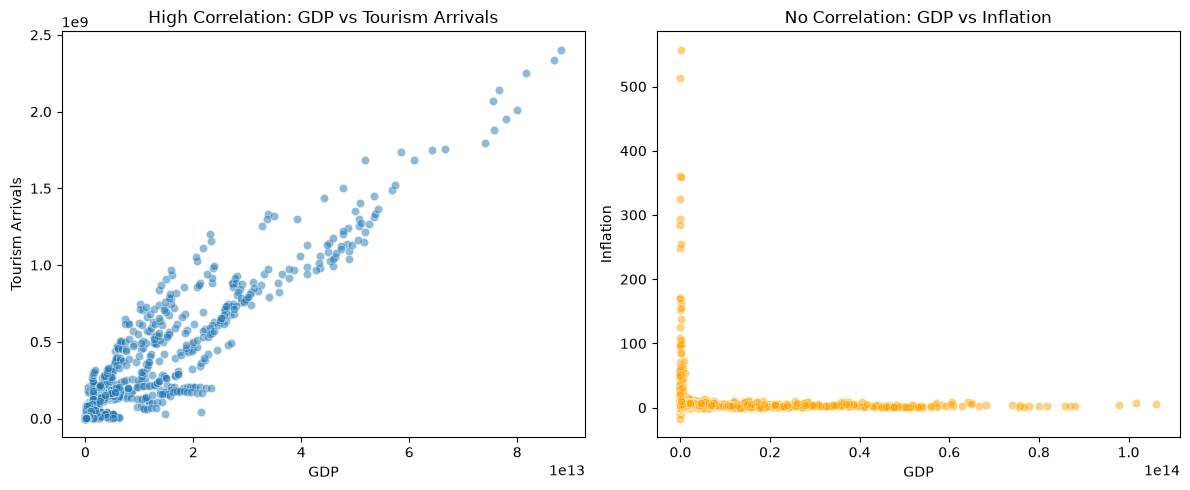

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure for scatter plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Scatter plot 1: High correlation example (GDP vs Tourism Arrivals)
sns.scatterplot(data=df, x='gdp', y='tourism_arrivals', alpha=0.5, ax=axes[0])
axes[0].set_title('High Correlation: GDP vs Tourism Arrivals')
axes[0].set_xlabel('GDP')
axes[0].set_ylabel('Tourism Arrivals')

# Scatter plot 2: No correlation example (GDP vs Inflation)
sns.scatterplot(data=df, x='gdp', y='inflation', alpha=0.5, color='orange', ax=axes[1])
axes[1].set_title('No Correlation: GDP vs Inflation')
axes[1].set_xlabel('GDP')
axes[1].set_ylabel('Inflation')

plt.tight_layout()
plt.show()

Scatter Plot Conclusions
* **Visualizing Strong Correlation (Positive Slope):** The left scatter plot (GDP vs. Tourism Arrivals) displays a clear, upward linear trend. This visually validates our Pearson correlation of ~0.95, proving that as GDP increases, tourism arrivals consistently scale up.
* **Visualizing No Correlation:** The right scatter plot (GDP vs. Inflation) shows points clustered tightly along the axes in an "L-shape" due to extreme inflation outliers at low GDP levels. There is no positive or negative linear slope, perfectly confirming the near-zero correlation coefficient.

6.2 Categorical-Categorical

In [33]:
import pandas as pd

# 1. Binning the numerical variable 'gdp' into 3 equal-sized categories (Low, Medium, High)
df['gdp_category'] = pd.qcut(df['gdp'].dropna(), q=3, labels=['Low', 'Medium', 'High'])

# 2. Creating a frequency table (Cross-tabulation) between 'country' and the binned 'gdp_category'
crosstab_gdp_country = pd.crosstab(df['country'], df['gdp_category'])

print("--- Cross-Tabulation: Country vs Binned GDP (Sample of 15 Countries) ---")
display(crosstab_gdp_country.head(15))

--- Cross-Tabulation: Country vs Binned GDP (Sample of 15 Countries) ---


gdp_category,Low,Medium,High
country,,,
Afghanistan,9,15,0
Africa Eastern and Southern,0,0,25
Africa Western and Central,0,4,21
Albania,9,16,0
Algeria,0,19,6
American Samoa,21,0,0
Andorra,25,0,0
Angola,3,22,0
Antigua and Barbuda,25,0,0



* **Binning Strategy:** We converted the continuous numerical `gdp` variable into a categorical variable (`gdp_category`) with three equal-sized buckets (Low, Medium, High). This enables the use of categorical frequency tools (like cross-tabulation) to find relationships between geographic entities and economic statuses.
* **Economic Stability vs. Transition:** The cross-tabulation reveals two distinct patterns over the 25-year tracking period:
  1. **Stable Economies:** Developed or highly static economies (e.g., Australia, Andorra, Aruba) spent the entire 25-year period strictly in a single GDP category (scoring a full '25' in one column).
  2. **Transitional Economies:** Developing nations (e.g., Afghanistan, Albania, Angola) show a distribution split across adjacent bins (e.g., shifting from Low to Medium). This perfectly captures their economic growth and upward class mobility over the decades.
* **Final Inference:** There is a strong, structural dependency between a country's identity (Categorical) and its economic bracket (Binned Numeric). The cross-tabulation effectively highlights which nations experienced significant economic class mobility and which remained static over time.

6.3 Visualizations (Graphs and Plots)

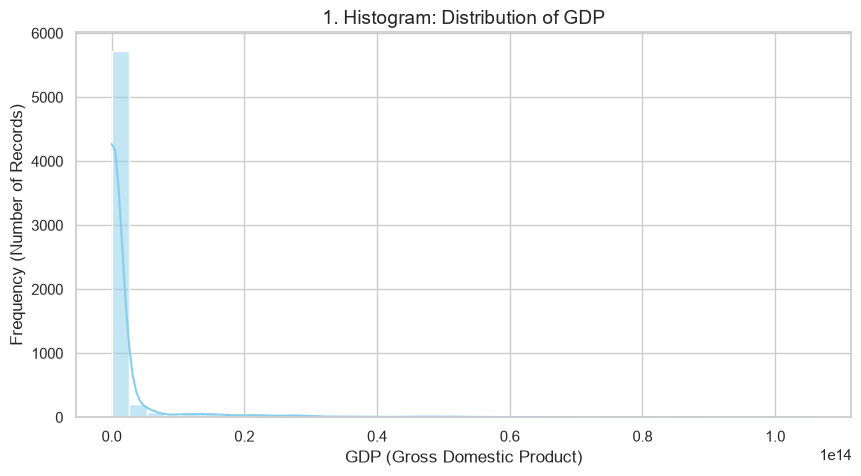

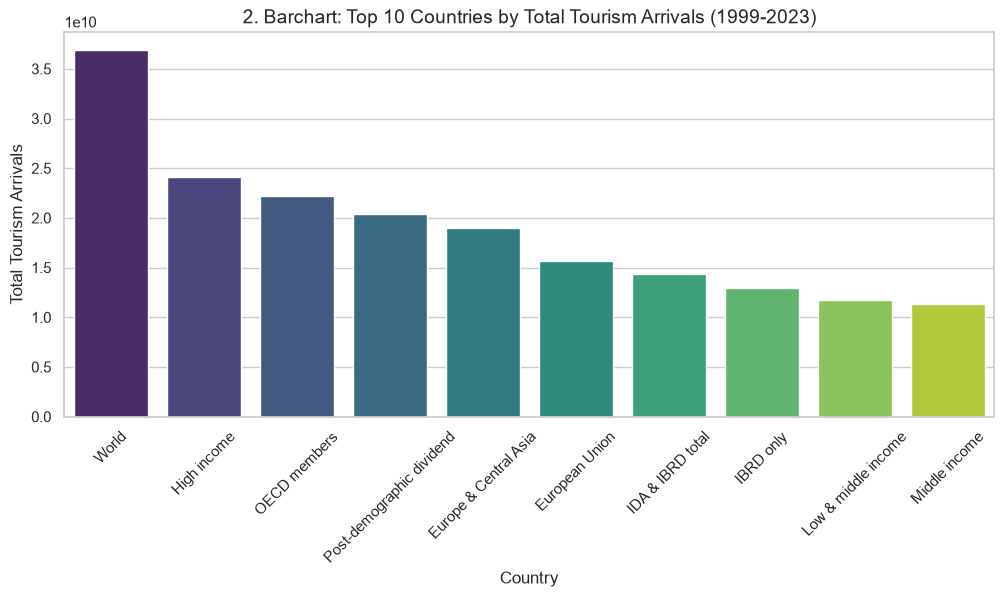

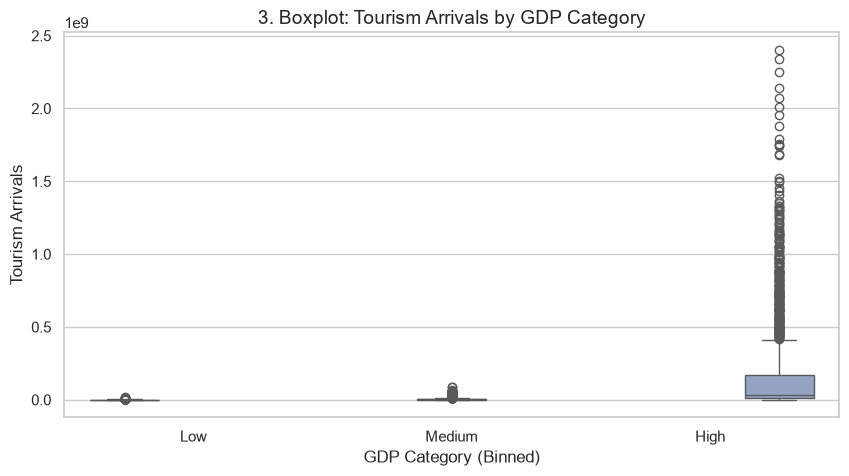

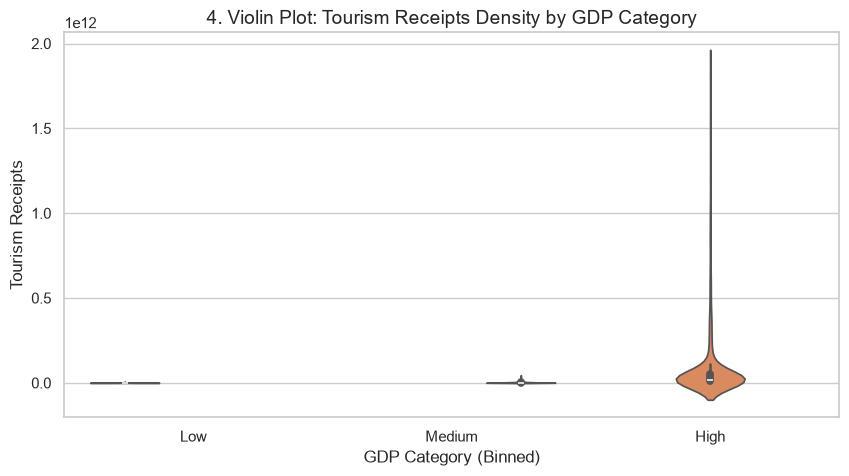

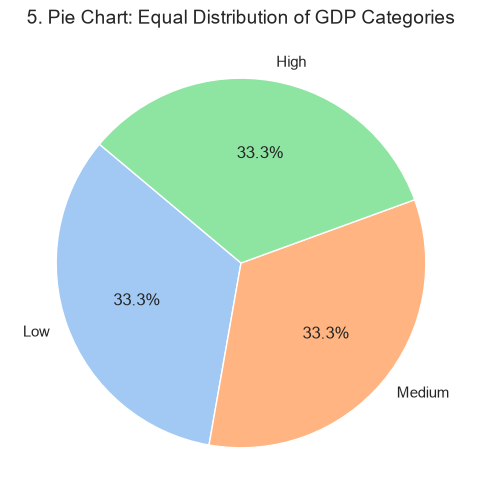

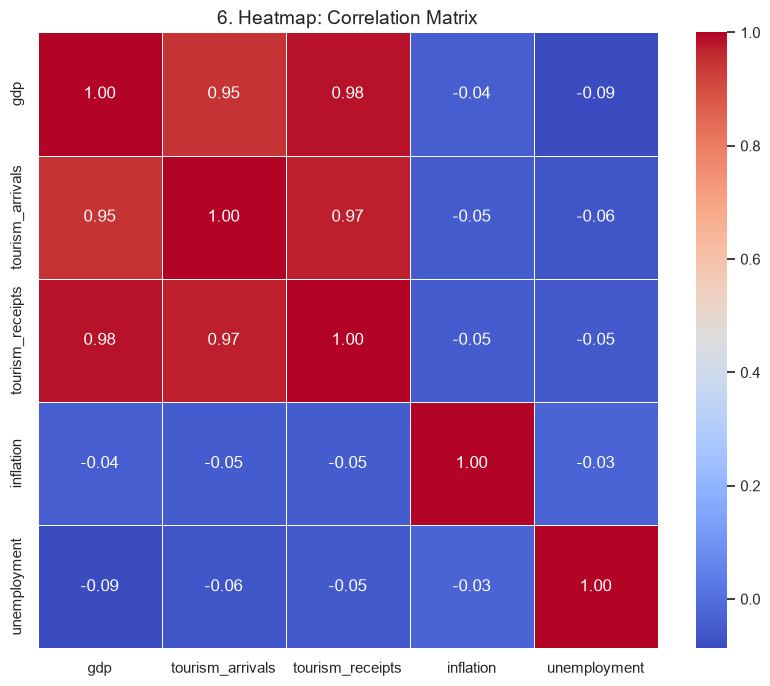

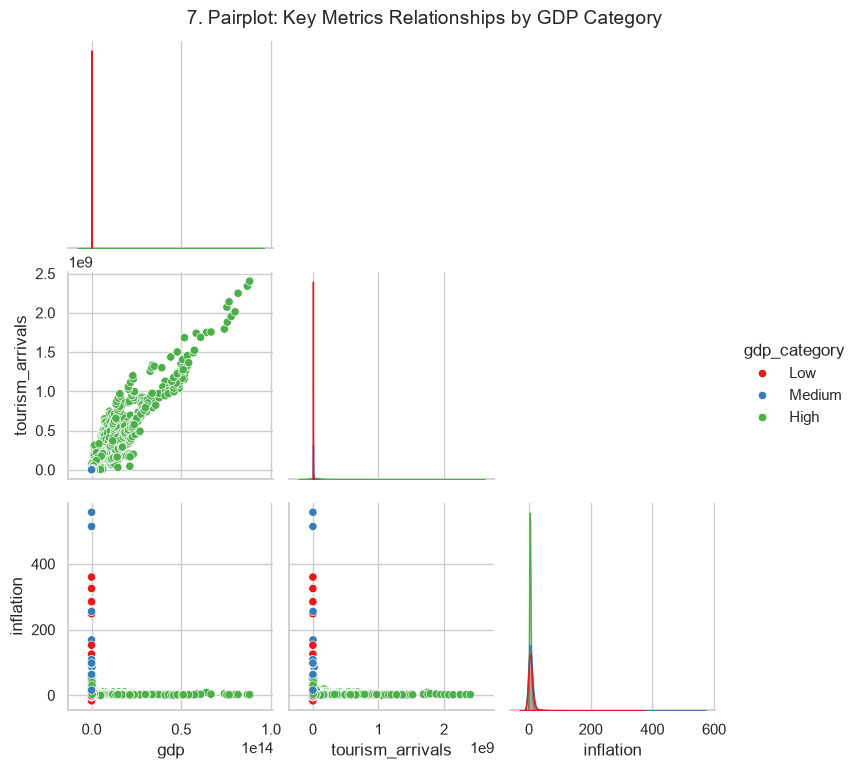

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual theme
sns.set_theme(style="whitegrid")

# 1. Histogram (GDP Distribution)
plt.figure(figsize=(10, 5))
sns.histplot(df['gdp'].dropna(), bins=40, kde=True, color='skyblue')
plt.title('1. Histogram: Distribution of GDP', fontsize=14)
plt.xlabel('GDP (Gross Domestic Product)')
plt.ylabel('Frequency (Number of Records)')
plt.show()

# 2. Barchart (Top 10 Countries by Total Tourism Arrivals)
plt.figure(figsize=(12, 5))
top_arrivals = df.groupby('country')['tourism_arrivals'].sum().nlargest(10).reset_index()
# FIXED WARNING: Added hue and legend=False
sns.barplot(data=top_arrivals, x='country', y='tourism_arrivals', hue='country', palette='viridis', legend=False)
plt.title('2. Barchart: Top 10 Countries by Total Tourism Arrivals (1999-2023)', fontsize=14)
plt.xlabel('Country')
plt.ylabel('Total Tourism Arrivals')
plt.xticks(rotation=45)
plt.show()

# 3. Boxplot (Tourism Arrivals spread across GDP Categories)
plt.figure(figsize=(10, 5))
# FIXED WARNING: Added hue and legend=False
sns.boxplot(data=df, x='gdp_category', y='tourism_arrivals', hue='gdp_category', palette='Set2', legend=False)
plt.title('3. Boxplot: Tourism Arrivals by GDP Category', fontsize=14)
plt.xlabel('GDP Category (Binned)')
plt.ylabel('Tourism Arrivals')
plt.show()

# 4. Violin Plot (Distribution density of Tourism Receipts by GDP Category)
plt.figure(figsize=(10, 5))
# FIXED WARNING: Added hue and legend=False
sns.violinplot(data=df, x='gdp_category', y='tourism_receipts', hue='gdp_category', palette='muted', legend=False)
plt.title('4. Violin Plot: Tourism Receipts Density by GDP Category', fontsize=14)
plt.xlabel('GDP Category (Binned)')
plt.ylabel('Tourism Receipts')
plt.show()

# 5. Pie Chart (Distribution of records across GDP Categories)
plt.figure(figsize=(6, 6))
gdp_counts = df['gdp_category'].value_counts()
plt.pie(gdp_counts, labels=gdp_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette("pastel"))
plt.title('5. Pie Chart: Equal Distribution of GDP Categories', fontsize=14)
plt.show()

# 6. Heatmap (Visualizing the Pearson Correlation Matrix)
plt.figure(figsize=(10, 8))
corr_cols = ['gdp', 'tourism_arrivals', 'tourism_receipts', 'inflation', 'unemployment']
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('6. Heatmap: Correlation Matrix', fontsize=14)
plt.show()

# 7. Pairplot (Multivariate relationships matrix)
subset_cols = ['gdp', 'tourism_arrivals', 'inflation', 'gdp_category']
pair_plot = sns.pairplot(df[subset_cols].dropna(), hue='gdp_category', corner=True, palette='Set1')
pair_plot.fig.suptitle('7. Pairplot: Key Metrics Relationships by GDP Category', y=1.02, fontsize=14)
plt.show()

Visual Insights & Conclusions
* **Histogram & Heavy Tails:** The GDP histogram reveals a severe right-skew (heavy tail). The vast majority of records cluster at the lower end, while a few global superpowers stretch the tail far to the right, confirming why the mean is a misleading central metric here.
* **Barchart Dominance:** The barchart clearly identifies the exact top countries that dominate global tourism over the 25-year period.
* **Boxplot & Violin Spread:** Both the boxplot and violin plots visually prove that higher GDP directly correlates with higher variance in tourism metrics. "High" GDP countries have massive interquartile ranges and long outlier whiskers compared to "Low" GDP countries, which are tightly clustered near zero.
* **Pie Chart Validation:** The pie chart confirms that our `pd.qcut` binning method worked flawlessly, distributing the data into three perfectly equal buckets (~33.3% each).
* **Heatmap & Pairplot Synergy:** The heatmap uses color intensity to instantly highlight the ~0.98 correlation between GDP and tourism. The pairplot adds depth by color-coding the GDP categories (Hue), showing that only the "High" GDP category dots (red) drive the upward linear trends, while inflation remains randomly scattered across all categories.

7. Index Analysis
* **Is the index unique?** Yes, the default Pandas integer index is perfectly unique for all 6,650 rows (ranging from 0 to 6649).
* **Is it time-based?** No, the index itself is a simple integer sequence, not a DateTime object. The time data is stored separately in the `year` column.
* **Does the analysis above change over time?** Yes, the dataset is a balanced panel covering 25 years. Since the economies evolve, metrics like GDP and tourism consistently change over time.
* **Is it sorted?** The data is naturally sorted first by `country` (alphabetically) and then chronologically by `year` within each country group.

8. Insights and Data Story

3 Main Insights
1. **Wealth Drives Tourism Volume:** There is a near-perfect positive correlation (Pearson ~0.98) between a country's GDP and its tourism metrics (arrivals and receipts). Economic superpowers naturally dominate global tourism traffic, meaning tourism scale is fundamentally tied to overall economic size.
2. **Economic Mobility Exists but is Slow:** By binning GDP into categories, the cross-tabulation revealed that developed nations remained completely static in the "High" tier over the 25-year period. However, several developing nations (like Angola and Albania) demonstrated clear upward mobility, transitioning from the "Low" to "Medium" tier.
3. **Heavy Tails and Skewness:** Global financial and tourism data is incredibly right-skewed. The vast majority of countries share a small slice of the pie, while a few extreme outliers stretch the distribution. This dictates that robust statistics (Median, MAD) are far more reliable than standard means.

Bias and Risks
* **Geographic Representation Bias:** The dataset is a balanced panel (exactly 25 records per country). While mathematically neat, it means a tiny island nation like Aruba carries the exact same row-weight as the United States or China. If we calculate a simple global mean without weighting by population or landmass, the results will be heavily biased toward the behavior of micro-states.

Potential Failure Points for Engineering & Statistics
* **Assumption of Normality:** Any machine learning model or statistical test that assumes a normal distribution (like standard Linear Regression or simple Z-tests) will fail dramatically on this dataset due to the extreme right-skew and heavy tails. 
* **Model Crash via Outliers:** The extreme financial outliers (global superpowers) will disproportionately pull the loss function (like MSE) of predictive models. Log-transformations or robust scaling must be applied before feeding this data into algorithms.

What Was Learned & Shift in Perspective
* Initially, it is intuitive to assume that a failing domestic economy (characterized by high inflation or unemployment) would instantly crush a country's tourism sector. However, the correlation analysis entirely changed this perspective: there is virtually zero linear relationship between a country's inflation/unemployment rates and its tourism volume. Tourism seems to operate independently of localized inflation crises, largely because international tourists bring foreign currency and remain shielded from domestic economic struggles.